# 03 — Selección de modelos candidatos

## Actividad 2.13, cierre científico

Este cuaderno cierra la selección metodológica. Explora los CSV de la actividad 2.12, contrasta esas formas con la literatura revisada y puntúa familias de modelos. **No entrena modelos, no calcula errores de predicción y no declara un modelo más exacto.**

La síntesis está en `docs/estudio_modelos_2_13.md`. El ajuste, si se autoriza, es la actividad 2.14.

Las frases se leen así:

- **Publicado:** está en un texto citado. Aquí solo se resume.
- **Comprobado en esta ejecución:** lo calcula una celda a partir de los CSV.
- **Hipótesis:** se formula para contrastarla después. No es un resultado.
- **Decisión:** es una elección de este laboratorio, no una ley física.


## 3.1. Introducción y problemática

La magnitud que se quiere predecir es `dp2_3_psi`: el incremento de presión leído en la columna `DP2-3`, interpretado como el de la etapa 3, en psi. La certeza de ese enlace es media y está en el diccionario. El gas libre reduce el aumento de presión de una ESP y puede volver inestable la operación (Zhu et al., 2019). Ese artículo no ajusta la curva completa de presión. Construye fronteras entre cuatro patrones de flujo.

Hay dos protocolos en los Excel, descritos en Zhu et al. (2019) y en la tesis de Zhu (2017):

- **Mapping.** El caudal de gas queda fijo, como Qgd, y el caudal de líquido recorre la curva. `Single Phase` es la curva de agua: `qgd` queda vacío y no se rellena con cero.
- **Surging.** El líquido queda fijo en una fracción del caudal de mejor eficiencia y aumenta el gas de admisión, registrado como `gvf0_porcentaje`.

No comparten la misma entrada de líquido ni la misma entrada de gas. Unirlos exigiría inventar la columna que el otro protocolo no midió. **Decisión:** se analizan por separado.


## 3.2. Pregunta científica e hipótesis

**Pregunta principal.** ¿Qué familias pueden representar `dp2_3_psi` en cada protocolo, con las columnas que sí existen, sin partir una curva entre entrenamiento y prueba?

La pregunta por el modelo más exacto no se responde aquí.

Hipótesis, no demostradas por este cuaderno:

- **H1.** Dentro de una curva, la relación entre la abscisa experimental y `dp2_3_psi` no es una sola recta. Si la pendiente local cambia de magnitud, un modelo solo lineal queda corto como representación, aunque siga siendo la referencia de comparación.
- **H2.** Al aumentar el gas, el incremento de presión baja respecto de la curva de agua, y algunas curvas muestran tramos de pendiente local positiva. Eso es compatible con un cambio de comportamiento. No demuestra, por sí solo, un cambio de régimen.
- **H3.** Con 30 curvas de mapping y 18 de surging, un modelo con muchos parámetros libres no se puede validar de forma honesta si cada curva se deja fuera entera.
- **H4.** Comparar la curva con gas con la curva de agua de la misma hoja y la misma velocidad mejora la lectura física en mapping. En surging esa referencia no está en la tabla.

Gamboa y Prado (2011), citados por Zhu et al. (2019), asocian quiebres de la curva H–Q con cambios de patrón. Esa asociación es literatura. Un cambio de signo de la pendiente local en estos CSV es solo una observación.


## 3.3. Materiales y métodos

**Procedencia.** Los Excel son el conjunto de Jianjun Zhu en Mendeley Data, versión 1, DOI 10.17632/fk2b4r69bs.1, licencia CC BY 4.0. El artículo asociado es Zhu et al. (2019), DOI 10.1016/j.petrol.2019.05.059. Este laboratorio no midió los ensayos.

**Archivos.** Se leen `data/processed/mapping_long.csv` y `data/processed/surging_long.csv`. No se escriben. Las huellas esperadas son las de la actividad 2.12. También se comprueban las huellas de los Excel, sin abrirlos para editarlos.

**Unidades de trabajo.** Caudal de líquido en bpd, como interpretación de alta certeza. `dp2_3_psi` en psi, certeza media. Qgd adimensional. `gvf0_porcentaje` en porcentaje, sin dividir por 100; el sufijo 0 no está definido en la tesis. Velocidad en rpm. Presión de separador en psig, tomada del nombre de la hoja.

**Curva independiente.** En mapping: hoja, velocidad y condición. En surging: hoja, velocidad y fracción de QBEP. Los puntos de una curva no son ensayos independientes.

**Inclusión.** Toda fila de los dos CSV. No hay pares a medio llenar: la actividad 2.12 ya dejó solo pares numéricos completos.

**Exclusión de cálculos.** No se imputa `qgd`. No se calcula el caudal de gas a 1800 rpm con el Qmax de 3500 rpm. No se multiplica la fracción de QBEP por 2700 bpd a 1800 rpm. No se apilan las tablas.

**Qué es y qué no es un modelo en este cuaderno.** Una pendiente entre dos puntos consecutivos es una descripción de la poligonal medida. El cociente de presiones de agua entre dos velocidades, comparado con $(N_1/N_2)^2$, es un diagnóstico de semejanza, no un ajuste. Ninguna celda llama a un estimador de scikit-learn.

**Emparejamiento exploratorio con la curva de agua.** Para cada punto con gas se busca el punto de agua de la misma hoja y la misma velocidad cuyo caudal esté más cerca. Se acepta el par si la distancia es menor que 80 bpd o que el 15 % del caudal del punto con gas. Esos umbrales son una regla de lectura, fijada antes de mirar el signo de la diferencia. No son parámetros estimados.

**Bibliografía.** Lo marcado como leído en este cierre es el texto local de Zhu et al. (2019), la tesis de 2017 en lo ya usado por el diccionario, el artículo de 2018 sobre surfactante, y los resúmenes o fichas de las referencias nuevas. Una ficha no equivale a haber reescrito las ecuaciones del artículo.


In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats


def encontrar_raiz_laboratorio() -> Path:
    candidato = Path.cwd().resolve()
    for _ in range(6):
        mapping = candidato / "data" / "raw" / "mapping.xlsx"
        surging = candidato / "data" / "raw" / "surging.xlsx"
        if mapping.is_file() and surging.is_file():
            return candidato
        if candidato.parent == candidato:
            break
        candidato = candidato.parent
    raise FileNotFoundError(
        "No se encontró data/raw/mapping.xlsx junto a data/raw/surging.xlsx."
    )


def huella_sha256(ruta: Path) -> str:
    digest = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1 << 20), b""):
            digest.update(bloque)
    return digest.hexdigest()


HUELLAS = {
    "data/raw/mapping.xlsx": "3b933ca84911484f5d912a44b025f5589abaf5ebc2b0426bf80c083869762bda",
    "data/raw/surging.xlsx": "acdcc6c5fc3d8969280c8712c45657fbb863f163a60829584fece5abf75f28cd",
    "data/processed/mapping_long.csv": "ff68e36703d3d3901b8bd964008c49b062afa9d89a817b9d66e7849f9b400648",
    "data/processed/surging_long.csv": "f58e8e2cac74acdf2081479ec8769422f39c4e4665f5b3ff472df4a70b15bd96",
}

RAIZ = encontrar_raiz_laboratorio()
for relativo, esperada in HUELLAS.items():
    obtenida = huella_sha256(RAIZ / relativo)
    if obtenida != esperada:
        raise RuntimeError(f"La huella de {relativo} cambió.")
    print(f"{relativo}: huella igual a la publicada")

mapping = pd.read_csv(RAIZ / "data" / "processed" / "mapping_long.csv")
surging = pd.read_csv(RAIZ / "data" / "processed" / "surging_long.csv")

if len(mapping) != 570 or len(surging) != 387:
    raise RuntimeError("El número de filas no coincide con la actividad 2.12.")
pares_50 = int((mapping["hoja"] == "50psig").sum())
if pares_50 != 186:
    raise RuntimeError("Mapping/50psig ya no tiene 186 pares.")
if int(mapping["qgd"].isna().sum()) != int((mapping["condicion"] == "Single Phase").sum()):
    raise RuntimeError("El vacío de qgd ya no coincide con Single Phase.")

print(f"Mapping: {len(mapping)} filas. Surging: {len(surging)} filas. 50psig: {pares_50} pares.")
print("Los CSV no se modifican en este cuaderno.")


data/raw/mapping.xlsx: huella igual a la publicada
data/raw/surging.xlsx: huella igual a la publicada
data/processed/mapping_long.csv: huella igual a la publicada
data/processed/surging_long.csv: huella igual a la publicada
Mapping: 570 filas. Surging: 387 filas. 50psig: 186 pares.
Los CSV no se modifican en este cuaderno.


In [2]:
def resumir_curvas_mapping(tabla: pd.DataFrame) -> pd.DataFrame:
    filas = []
    for (hoja, velocidad, condicion), grupo in tabla.groupby(
        ["hoja", "velocidad_rpm", "condicion"], sort=False
    ):
        grupo = grupo.sort_values("ql_bpd")
        caudal = grupo["ql_bpd"].to_numpy()
        presion = grupo["dp2_3_psi"].to_numpy()
        delta_q = np.diff(caudal)
        delta_p = np.diff(presion)
        utiles = np.abs(delta_q) > 1e-9
        pendiente = delta_p[utiles] / delta_q[utiles]
        signo = np.sign(pendiente)
        signo[np.abs(pendiente) < 1e-4] = 0
        cambios = int(np.sum((signo[1:] * signo[:-1]) < 0)) if len(signo) > 1 else 0
        rho = np.nan
        if len(grupo) >= 3 and np.unique(caudal).size >= 3:
            rho = float(stats.spearmanr(caudal, presion).statistic)
        filas.append(
            {
                "hoja": hoja,
                "velocidad_rpm": int(velocidad),
                "condicion": condicion,
                "n": len(grupo),
                "ql_min_bpd": float(caudal.min()),
                "ql_max_bpd": float(caudal.max()),
                "dp_min_psi": float(presion.min()),
                "dp_max_psi": float(presion.max()),
                "pendiente_mediana_psi_por_bpd": float(np.median(pendiente)),
                "fraccion_tramos_negativos": float(np.mean(pendiente < 0)),
                "cambios_de_signo": cambios,
                "spearman_ql_dp": rho,
                "origen_velocidad": grupo["origen_velocidad"].iloc[0],
            }
        )
    return pd.DataFrame(filas)


def resumir_curvas_surging(tabla: pd.DataFrame) -> pd.DataFrame:
    filas = []
    for (hoja, velocidad, condicion), grupo in tabla.groupby(
        ["hoja", "velocidad_rpm", "condicion"], sort=False
    ):
        grupo = grupo.sort_values("gvf0_porcentaje")
        gas = grupo["gvf0_porcentaje"].to_numpy()
        presion = grupo["dp2_3_psi"].to_numpy()
        delta_g = np.diff(gas)
        delta_p = np.diff(presion)
        utiles = np.abs(delta_g) > 1e-12
        pendiente = delta_p[utiles] / delta_g[utiles]
        signo = np.sign(pendiente)
        signo[np.abs(pendiente) < 1e-4] = 0
        cambios = int(np.sum((signo[1:] * signo[:-1]) < 0)) if len(signo) > 1 else 0
        rho = np.nan
        if len(grupo) >= 3 and np.unique(gas).size >= 3:
            rho = float(stats.spearmanr(gas, presion).statistic)
        filas.append(
            {
                "hoja": hoja,
                "velocidad_rpm": int(velocidad),
                "condicion": condicion,
                "n": len(grupo),
                "gvf_min": float(gas.min()),
                "gvf_max": float(gas.max()),
                "dp_inicial_psi": float(presion[0]),
                "dp_final_psi": float(presion[-1]),
                "dp_min_psi": float(presion.min()),
                "dp_max_psi": float(presion.max()),
                "pendiente_mediana_psi_por_punto_de_gvf": float(np.median(pendiente)),
                "fraccion_tramos_negativos": float(np.mean(pendiente < 0)),
                "cambios_de_signo": cambios,
                "spearman_gvf_dp": rho,
            }
        )
    return pd.DataFrame(filas)


curvas_mapping = resumir_curvas_mapping(mapping)
curvas_surging = resumir_curvas_surging(surging)
if len(curvas_mapping) != 30 or len(curvas_surging) != 18:
    raise RuntimeError("El número de curvas no coincide con el estudio.")

print("Curvas de mapping: 30. Puntos por curva:")
print(curvas_mapping["n"].agg(["min", "median", "max"]).to_string())
print("Curvas de surging: 18. Puntos por curva:")
print(curvas_surging["n"].agg(["min", "median", "max"]).to_string())
print()
print(
    "Mapping, dp2_3_psi: "
    f"{mapping['dp2_3_psi'].min():.4g} a {mapping['dp2_3_psi'].max():.4g} psi. "
    f"Caudal: {mapping['ql_bpd'].min():.4g} a {mapping['ql_bpd'].max():.4g} bpd."
)
print(
    "Surging, dp2_3_psi: "
    f"{surging['dp2_3_psi'].min():.4g} a {surging['dp2_3_psi'].max():.4g} psi. "
    f"GVF0: {surging['gvf0_porcentaje'].min():.4g} a {surging['gvf0_porcentaje'].max():.4g} %."
)
print("Filas de mapping con velocidad asignada por el diseño:", int((mapping["origen_velocidad"] == "diseño_experimental").sum()))
print("Surging, orígenes de velocidad:", sorted(surging["origen_velocidad"].unique()))


Curvas de mapping: 30. Puntos por curva:
min        9.0
median    20.0
max       30.0
Curvas de surging: 18. Puntos por curva:
min        8.0
median    22.0
max       42.0

Mapping, dp2_3_psi: 0.08009 a 31.21 psi. Caudal: 1.353 a 4703 bpd.
Surging, dp2_3_psi: 0.3828 a 27.96 psi. GVF0: 0.0005574 a 19.14 %.
Filas de mapping con velocidad asignada por el diseño: 384
Surging, orígenes de velocidad: ['celda']


## 3.4. Exploración científica de los datos

Cada gráfico usa los pares ya normalizados. La leyenda es la condición experimental. La fuente es el CSV de la actividad 2.12, a su vez copiado sin editar de Mendeley Data.

Una pendiente local es el cociente entre el cambio de `dp2_3_psi` y el cambio de la abscisa, entre dos puntos consecutivos de la misma curva. Un cambio de signo dice que la poligonal sube y baja. Puede ser un cambio de comportamiento, ruido de medición o un punto aislado. **No se etiqueta como régimen.**


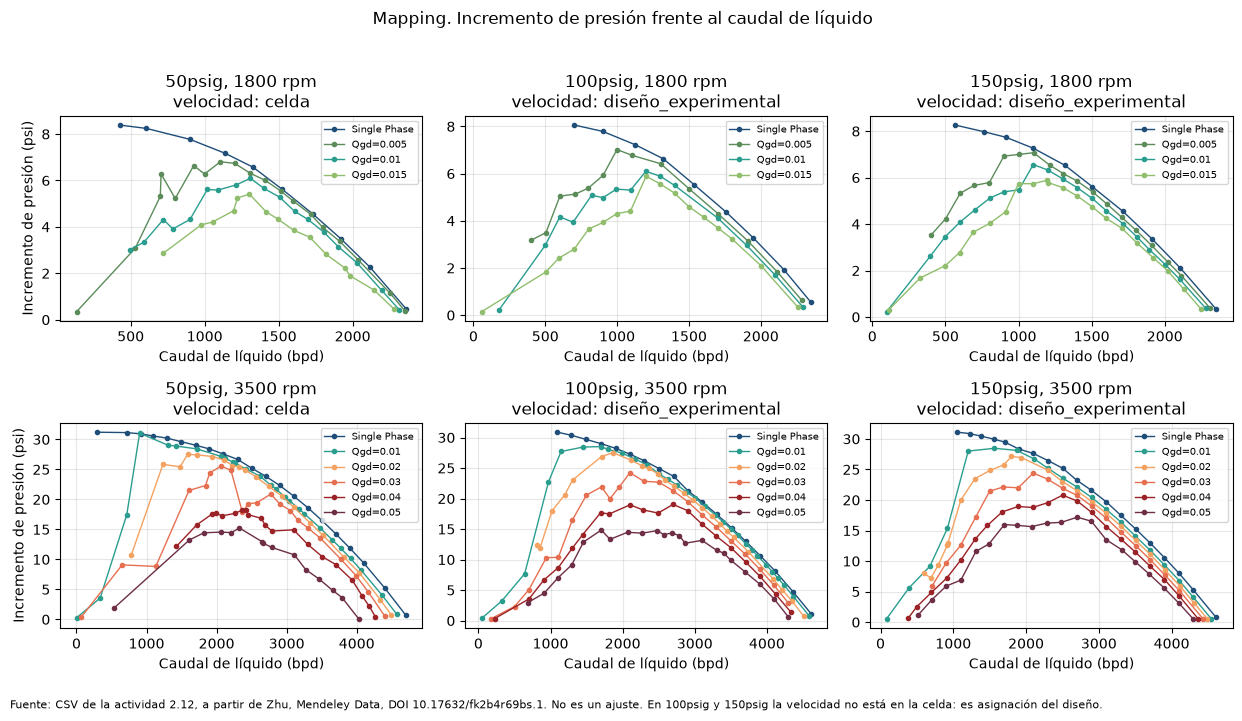

In [3]:
FUENTE = (
    "Fuente: CSV de la actividad 2.12, a partir de Zhu, Mendeley Data, "
    "DOI 10.17632/fk2b4r69bs.1. No es un ajuste."
)
COLORES = {
    "Single Phase": "#1f4e79",
    "Qgd=0.005": "#5b8c5a",
    "Qgd=0.01": "#2a9d8f",
    "Qgd=0.015": "#90be6d",
    "Qgd=0.02": "#f4a261",
    "Qgd=0.03": "#e76f51",
    "Qgd=0.04": "#9b2226",
    "Qgd=0.05": "#6d2e46",
    "0.75Qbep": "#1f4e79",
    "Qbep": "#e09f3e",
    "1.25Qbep": "#9b2226",
}


def dibujar_mapping(tabla, velocidades, titulo, nota):
    hojas = ["50psig", "100psig", "150psig"]
    fig, ejes = plt.subplots(len(velocidades), 3, figsize=(12.5, 3.6 * len(velocidades)), sharey=False)
    if len(velocidades) == 1:
        ejes = np.array([ejes])
    for i, velocidad in enumerate(velocidades):
        for j, hoja in enumerate(hojas):
            eje = ejes[i, j]
            sub = tabla[(tabla["hoja"] == hoja) & (tabla["velocidad_rpm"] == velocidad)]
            origen = sub["origen_velocidad"].iloc[0]
            for condicion, grupo in sub.groupby("condicion", sort=False):
                grupo = grupo.sort_values("ql_bpd")
                eje.plot(
                    grupo["ql_bpd"],
                    grupo["dp2_3_psi"],
                    marker="o",
                    ms=3,
                    lw=1,
                    color=COLORES.get(condicion, "gray"),
                    label=condicion,
                )
            eje.set_title(f"{hoja}, {velocidad} rpm\nvelocidad: {origen}")
            eje.set_xlabel("Caudal de líquido (bpd)")
            eje.grid(True, alpha=0.3)
            if j == 0:
                eje.set_ylabel("Incremento de presión (psi)")
            eje.legend(fontsize=7, loc="best")
    fig.suptitle(titulo)
    fig.text(0.01, 0.01, FUENTE + " " + nota, fontsize=8)
    fig.tight_layout(rect=(0, 0.04, 1, 0.96))
    plt.show()


dibujar_mapping(
    mapping,
    [1800, 3500],
    "Mapping. Incremento de presión frente al caudal de líquido",
    "En 100psig y 150psig la velocidad no está en la celda: es asignación del diseño.",
)


In [4]:
agua = curvas_mapping[curvas_mapping["condicion"] == "Single Phase"]
gas = curvas_mapping[curvas_mapping["condicion"] != "Single Phase"]
texto = f'''
**Lectura de las curvas de mapping, comprobada en esta ejecución.**

Hay {len(curvas_mapping)} curvas. Las {len(agua)} de agua tienen pendiente mediana negativa y {int((agua["cambios_de_signo"] > 0).sum())} cambios de signo. Las {len(gas)} curvas con gas tienen pendiente mediana negativa en {int((gas["pendiente_mediana_psi_por_bpd"] < 0).sum())} casos, y {int((gas["cambios_de_signo"] > 0).sum())} de ellas cambian de signo al menos una vez.

Eso sostiene, como observación, que la curva de agua baja al subir el caudal y que varias curvas con gas no son una poligonal monótona. No identifica el patrón de flujo. La separación vertical entre condiciones, sobre todo a 3500 rpm, es la pista visual de degradación. A 1800 rpm el incremento cabe en menos de unos 9 psi, así que la misma diferencia absoluta pesa más.
'''
display(Markdown(texto))



**Lectura de las curvas de mapping, comprobada en esta ejecución.**

Hay 30 curvas. Las 6 de agua tienen pendiente mediana negativa y 0 cambios de signo. Las 24 curvas con gas tienen pendiente mediana negativa en 23 casos, y 24 de ellas cambian de signo al menos una vez.

Eso sostiene, como observación, que la curva de agua baja al subir el caudal y que varias curvas con gas no son una poligonal monótona. No identifica el patrón de flujo. La separación vertical entre condiciones, sobre todo a 3500 rpm, es la pista visual de degradación. A 1800 rpm el incremento cabe en menos de unos 9 psi, así que la misma diferencia absoluta pesa más.


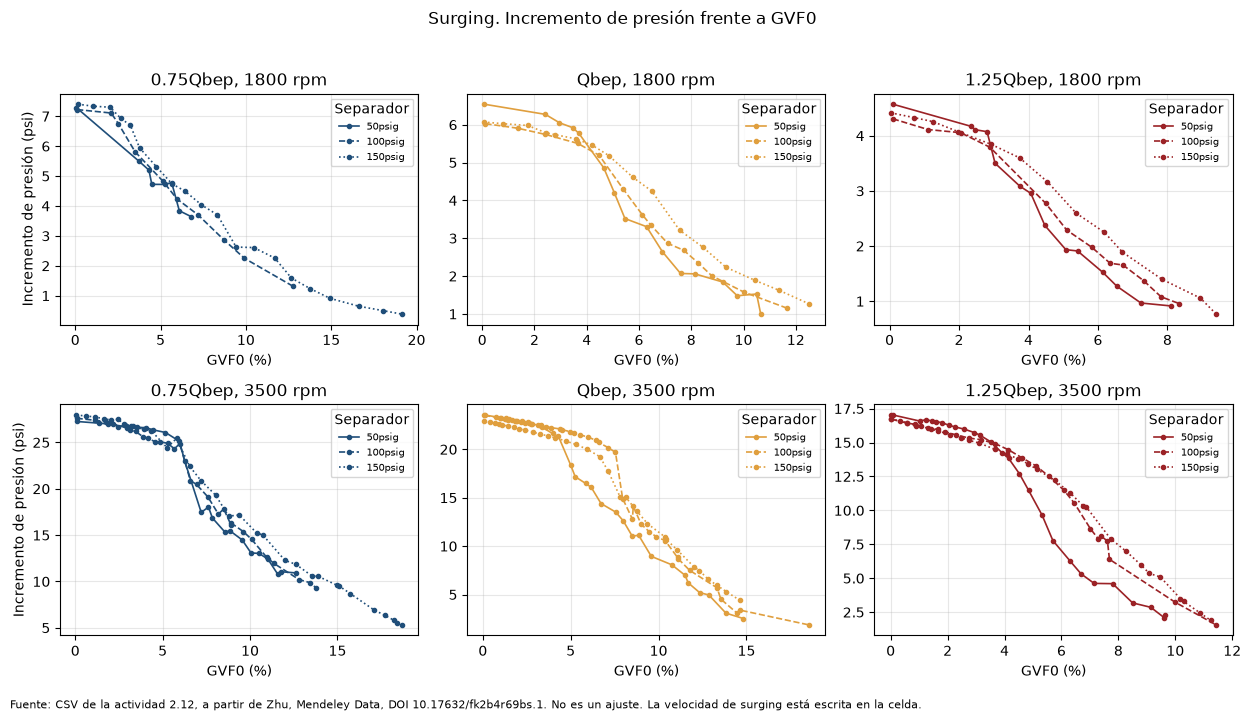


**Lectura de surging, comprobada en esta ejecución.**

En 18 de 18 curvas, el último punto, el de mayor GVF0, tiene menos presión que el primero. La pendiente mediana es negativa en 18 curvas. Hay cambio de signo en 9 curvas.

La tendencia de conjunto es una caída al aumentar GVF0. Los cambios de signo quedan como hipótesis de un tramo distinto, no como un régimen identificado. El color es la fracción de QBEP y el trazo es la presión del separador: no se lee un efecto limpio y separado de cada una sin un modelo, y este cuaderno no lo ajusta.


In [5]:
fig, ejes = plt.subplots(2, 3, figsize=(12.5, 7.2), sharex=False, sharey=False)
fracciones = ["0.75Qbep", "Qbep", "1.25Qbep"]
presiones = ["50psig", "100psig", "150psig"]
estilo = {"50psig": "-", "100psig": "--", "150psig": ":"}
for i, velocidad in enumerate([1800, 3500]):
    for j, fraccion in enumerate(fracciones):
        eje = ejes[i, j]
        for hoja in presiones:
            sub = surging[
                (surging["velocidad_rpm"] == velocidad)
                & (surging["condicion"] == fraccion)
                & (surging["hoja"] == hoja)
            ].sort_values("gvf0_porcentaje")
            eje.plot(
                sub["gvf0_porcentaje"],
                sub["dp2_3_psi"],
                marker="o",
                ms=3,
                lw=1.2,
                ls=estilo[hoja],
                color=COLORES[fraccion],
                label=hoja,
            )
        eje.set_title(f"{fraccion}, {velocidad} rpm")
        eje.set_xlabel("GVF0 (%)")
        eje.grid(True, alpha=0.3)
        if j == 0:
            eje.set_ylabel("Incremento de presión (psi)")
        eje.legend(fontsize=7, title="Separador")
fig.suptitle("Surging. Incremento de presión frente a GVF0")
fig.text(0.01, 0.01, FUENTE + " La velocidad de surging está escrita en la celda.", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
plt.show()

bajan = int((curvas_surging["dp_final_psi"] < curvas_surging["dp_inicial_psi"]).sum())
texto = f'''
**Lectura de surging, comprobada en esta ejecución.**

En {bajan} de {len(curvas_surging)} curvas, el último punto, el de mayor GVF0, tiene menos presión que el primero. La pendiente mediana es negativa en {int((curvas_surging["pendiente_mediana_psi_por_punto_de_gvf"] < 0).sum())} curvas. Hay cambio de signo en {int((curvas_surging["cambios_de_signo"] > 0).sum())} curvas.

La tendencia de conjunto es una caída al aumentar GVF0. Los cambios de signo quedan como hipótesis de un tramo distinto, no como un régimen identificado. El color es la fracción de QBEP y el trazo es la presión del separador: no se lee un efecto limpio y separado de cada una sin un modelo, y este cuaderno no lo ajusta.
'''
display(Markdown(texto))


In [6]:
def emparejar_con_agua(tabla: pd.DataFrame) -> pd.DataFrame:
    pares = []
    for (hoja, velocidad), bloque in tabla.groupby(["hoja", "velocidad_rpm"]):
        agua = bloque[bloque["condicion"] == "Single Phase"]
        gas = bloque[bloque["condicion"] != "Single Phase"]
        for _, punto in gas.iterrows():
            distancia = (agua["ql_bpd"] - punto["ql_bpd"]).abs()
            indice = distancia.idxmin()
            tolerancia = max(80.0, 0.15 * abs(float(punto["ql_bpd"])))
            if float(distancia.loc[indice]) <= tolerancia:
                referencia = agua.loc[indice]
                pares.append(
                    {
                        "hoja": hoja,
                        "velocidad_rpm": int(velocidad),
                        "condicion": punto["condicion"],
                        "ql_bpd": float(punto["ql_bpd"]),
                        "dp_gas_psi": float(punto["dp2_3_psi"]),
                        "dp_agua_psi": float(referencia["dp2_3_psi"]),
                        "diferencia_psi": float(punto["dp2_3_psi"] - referencia["dp2_3_psi"]),
                    }
                )
    return pd.DataFrame(pares)


pares_agua = emparejar_con_agua(mapping)
debajo = int((pares_agua["diferencia_psi"] < 0).sum())
texto = f'''
**Degradación respecto de la curva de agua, comprobada en esta ejecución.**

Se emparejaron {len(pares_agua)} puntos con gas con un punto de agua de la misma hoja y velocidad, dentro de la tolerancia fijada. En {debajo} de esos pares, {100 * debajo / len(pares_agua):.1f} %, la presión con gas es menor. La mediana de la diferencia es {pares_agua["diferencia_psi"].median():.2f} psi.

Es una comparación de puntos cercanos en caudal, no un efecto causal aislado y no es la presión normalizada de Zhu et al. (2018): falta la densidad de la mezcla. La diferencia mediana por velocidad es {pares_agua.groupby("velocidad_rpm")["diferencia_psi"].median().round(2).to_dict()} psi.
'''
display(Markdown(texto))
print("Pares aceptados por velocidad:")
print(pares_agua.groupby("velocidad_rpm").size().to_string())



**Degradación respecto de la curva de agua, comprobada en esta ejecución.**

Se emparejaron 434 puntos con gas con un punto de agua de la misma hoja y velocidad, dentro de la tolerancia fijada. En 422 de esos pares, 97.2 %, la presión con gas es menor. La mediana de la diferencia es -2.15 psi.

Es una comparación de puntos cercanos en caudal, no un efecto causal aislado y no es la presión normalizada de Zhu et al. (2018): falta la densidad de la mezcla. La diferencia mediana por velocidad es {1800: -1.01, 3500: -3.28} psi.


Pares aceptados por velocidad:
velocidad_rpm
1800    141
3500    293


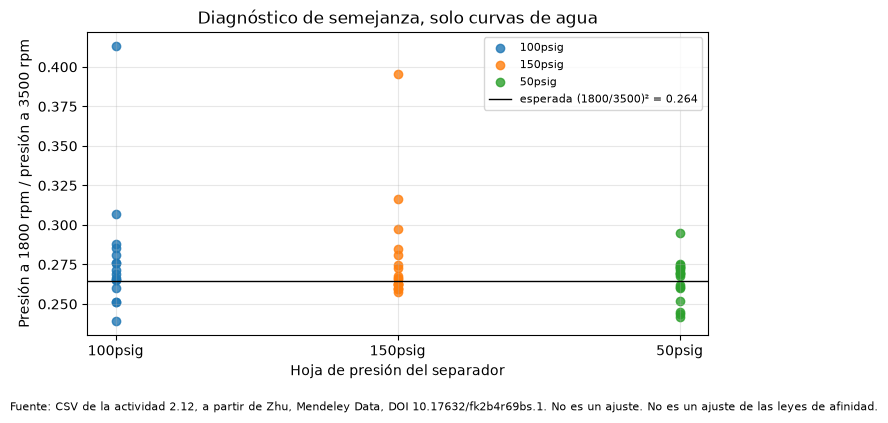


**Semejanza de las curvas de agua, comprobada en esta ejecución.**

La tesis escribe, citando a Stepanoff (1957), que la altura escala con el cuadrado de la velocidad. La razón esperada entre 1800 y 3500 rpm es 0.264. En 52 pares de agua con caudal aproximadamente semejante, la mediana observada es 0.268.

Esto no valida la ley para el flujo con gas. En 100psig y 150psig la velocidad de 1800 y 3500 rpm es asignación del diseño, no una celda. El diagnóstico queda como coherencia aproximada de las curvas de agua, no como modelo del gas.


         count    median
hoja                    
100psig     16  0.269967
150psig     18  0.266072
50psig      18  0.269097


In [7]:
ratio_n = 1800 / 3500
ratio_h = ratio_n ** 2
razones = []
agua = mapping[mapping["condicion"] == "Single Phase"]
for hoja, bloque in agua.groupby("hoja"):
    baja = bloque[bloque["velocidad_rpm"] == 1800]
    alta = bloque[bloque["velocidad_rpm"] == 3500]
    for _, punto in alta.iterrows():
        caudal_esperado = punto["ql_bpd"] * ratio_n
        distancia = (baja["ql_bpd"] - caudal_esperado).abs()
        indice = distancia.idxmin()
        if float(distancia.loc[indice]) <= max(80.0, 0.20 * max(caudal_esperado, 1.0)):
            dp_baja = float(baja.loc[indice, "dp2_3_psi"])
            dp_alta = float(punto["dp2_3_psi"])
            if dp_baja > 1 and dp_alta > 1:
                razones.append(
                    {
                        "hoja": hoja,
                        "razon_observada": dp_baja / dp_alta,
                        "origen_1800": baja["origen_velocidad"].iloc[0],
                    }
                )
razones = pd.DataFrame(razones)
fig, eje = plt.subplots(figsize=(7.2, 4.2))
for hoja, grupo in razones.groupby("hoja"):
    eje.scatter(
        np.full(len(grupo), list(razones["hoja"].unique()).index(hoja)),
        grupo["razon_observada"],
        label=hoja,
        alpha=0.8,
    )
eje.axhline(ratio_h, color="black", lw=1, label=f"esperada (1800/3500)² = {ratio_h:.3f}")
eje.set_xticks(range(razones["hoja"].nunique()))
eje.set_xticklabels(list(razones["hoja"].unique()))
eje.set_ylabel("Presión a 1800 rpm / presión a 3500 rpm")
eje.set_xlabel("Hoja de presión del separador")
eje.set_title("Diagnóstico de semejanza, solo curvas de agua")
eje.legend(fontsize=8)
eje.grid(True, alpha=0.3)
fig.text(0.01, 0.01, FUENTE + " No es un ajuste de las leyes de afinidad.", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()
texto = f'''
**Semejanza de las curvas de agua, comprobada en esta ejecución.**

La tesis escribe, citando a Stepanoff (1957), que la altura escala con el cuadrado de la velocidad. La razón esperada entre 1800 y 3500 rpm es {ratio_h:.3f}. En {len(razones)} pares de agua con caudal aproximadamente semejante, la mediana observada es {razones["razon_observada"].median():.3f}.

Esto no valida la ley para el flujo con gas. En 100psig y 150psig la velocidad de 1800 y 3500 rpm es asignación del diseño, no una celda. El diagnóstico queda como coherencia aproximada de las curvas de agua, no como modelo del gas.
'''
display(Markdown(texto))
print(razones.groupby("hoja")["razon_observada"].agg(["count", "median"]).to_string())


In [8]:
print("Cobertura de mapping: puntos por hoja, velocidad y origen")
print(
    mapping.groupby(["hoja", "velocidad_rpm", "origen_velocidad"]).size().to_string()
)
print()
print("Condiciones presentes")
for clave, grupo in mapping.groupby(["hoja", "velocidad_rpm"]):
    print(clave, sorted(grupo["condicion"].unique()))
print()
print("Surging: las 18 combinaciones de hoja, velocidad y fracción están presentes.")
print(surging.groupby(["hoja", "velocidad_rpm", "condicion"]).size().unstack("condicion").to_string())
print()
print("Regiones pobres, leídas de los mínimos de caudal y de GVF0:")
print(
    "El caudal de mapping llega a "
    f"{mapping['ql_bpd'].min():.3g} bpd en una curva con gas a 3500 rpm y 50 psig. "
    "Varias curvas de agua a 3500 rpm empiezan por encima de 1000 bpd, así que el emparejamiento con agua no cubre el extremo de caudal bajo."
)
print(
    "GVF0 de surging llega a "
    f"{surging['gvf0_porcentaje'].max():.3g} %. No hay filas por encima de ese valor. "
    "Qgd de mapping no pasa de 0.05, y 0.005 y 0.015 solo aparecen en el diseño de 1800 rpm."
)


Cobertura de mapping: puntos por hoja, velocidad y origen
hoja     velocidad_rpm  origen_velocidad   
100psig  1800           diseño_experimental     55
         3500           diseño_experimental    137
150psig  1800           diseño_experimental     70
         3500           diseño_experimental    122
50psig   1800           celda                   62
         3500           celda                  124

Condiciones presentes
('100psig', 1800) ['Qgd=0.005', 'Qgd=0.01', 'Qgd=0.015', 'Single Phase']
('100psig', 3500) ['Qgd=0.01', 'Qgd=0.02', 'Qgd=0.03', 'Qgd=0.04', 'Qgd=0.05', 'Single Phase']
('150psig', 1800) ['Qgd=0.005', 'Qgd=0.01', 'Qgd=0.015', 'Single Phase']
('150psig', 3500) ['Qgd=0.01', 'Qgd=0.02', 'Qgd=0.03', 'Qgd=0.04', 'Qgd=0.05', 'Single Phase']
('50psig', 1800) ['Qgd=0.005', 'Qgd=0.01', 'Qgd=0.015', 'Single Phase']
('50psig', 3500) ['Qgd=0.01', 'Qgd=0.02', 'Qgd=0.03', 'Qgd=0.04', 'Qgd=0.05', 'Single Phase']

Surging: las 18 combinaciones de hoja, velocidad y fracción están 

## 3.5. Análisis de factibilidad

La puntuación de la sección siguiente usa esta lectura. Un modelo predictivo propone un número de psi para una curva no usada al estimarlo. Una transformación reescribe variables. Una correlación semiempírica compara con una referencia medida, aquí la curva de agua. Un diagnóstico físico no predice el gas.

| Familia | Qué representa | Fundamento | Variables que pide | ¿Están? | Forma observada | Parámetros, antes de ajustarlos | ¿Cabe en 30 y 18 curvas? | Lectura física | Sobreajuste | Fuera del rango |
|---|---|---|---|---|---|---|---|---|---|---|
| Lineal múltiple | Un plano de psi | Suma de entradas con coeficientes | Caudal o fracción, gas, rpm, psig | Sí, por protocolo | La pendiente mediana es negativa, pero dentro de la curva la pendiente cambia | Un coeficiente por entrada | Sí | El signo del gas puede leerse; no hay quiebre | Bajo si las entradas son pocas | No se extrapola de rpm ni de fluido |
| Polinomio de grado 2 con cresta | Una superficie curva | Potencias y productos; Hoerl y Kennard (1970) suman una penalización a la diagonal | Las mismas | Sí | Hay cambio de magnitud de la pendiente | El grado se fija en 2 antes de la prueba; la penalización, fuera de las curvas de prueba | Aceptable si el grado no se elige con la prueba | Media: curva, no ley de bomba | Sube con los productos | Oscila fuera del caudal ensayado |
| Lineal por la condición ya escrita | Una recta por Qgd o por fracción de QBEP | El diseño ya separa esas curvas | La condición, que es una etiqueta del archivo | Sí | Cada condición es una curva distinta | Una recta compartida entre hojas y velocidades de la misma etiqueta, no una recta por curva | Sí, porque la etiqueta se repite; 0,005 y 0,015 no están en las hojas de 3500 rpm | Alta: respeta el bloque experimental | Bajo dentro de cada etiqueta | Una etiqueta nueva no tiene recta |
| Cociente respecto del agua | Degradación en mapping | Presión con gas frente a la presión de agua a caudal cercano | Curva de agua de la misma hoja y velocidad | Solo mapping | Los pares cercanos caen, en su mayoría, por debajo del agua | No estima geometría; el emparejamiento es una regla | La curva de agua es una entrada medida, no un trozo de la curva con gas | Alta en mapping; no es el Np de 2018 | Bajo | Sin agua a esa velocidad no hay cociente |
| Bosque aleatorio poco profundo | Cortes locales de la superficie | Breiman (2001) | Las mismas entradas | Sí | Puede seguir un tramo que cambia de signo | Profundidad y número de árboles, fijados fuera de la prueba | Justo: 30 y 18 bloques | Baja | Alto si el árbol crece hasta el punto | Mala extrapolación |
| Boosting | Suma de árboles sobre el resto | Friedman (2001) | Las mismas | Sí | También puede seguir quiebres locales | Más decisiones que el bosque | Débil | Baja | Alto | La misma mala extrapolación |
| Vectores de soporte | Curva con margen y núcleo | Smola y Schölkopf (2004) | Entradas escaladas | Sí, tras una escala | Curvatura suave | Núcleo y margen | Justo | Baja | Medio | Depende del núcleo |
| Modelo aditivo | Una función suave por entrada | Hastie y Tibshirani (1986) | Las mismas | Sí | Curvatura por entrada, sin el producto gas por caudal salvo que se añada | Grados de suavidad | Aceptable | Media | Medio | Mala si la spline se deja libre |
| Proceso gaussiano | Media y varianza | Rasmussen y Williams (2006) | Las mismas | Sí | Curvatura y una banda | Parámetros del núcleo | Débil con 30 curvas | La banda sí ayuda a no extrapolar | Alto si el núcleo absorbe la curva | La banda ancha no es una predicción útil |
| Red densa | Superficie compuesta | Hornik, Stinchcombe y White (1989), capacidad, no garantía con esta muestra | Entradas escaladas | Sí | Cualquier superficie continua | Muchos pesos | No, para una red que no esté ya casi vacía | Muy baja | Alto | Opaca |
| Árboles muy aleatorizados | Otra variante del bosque | Geurts, Ernst y Wehenkel (2006) | Las mismas | Sí | La misma que el bosque | Similar | La misma | Baja | Alto | La misma |
| Mecanicista de 2019 como psi | Fronteras de patrón, no la columna | Zhu et al. (2019), secciones 5 y 7 | Geometría y cierres | No | No produce `dp2_3_psi` con estas columnas | No se cuentan: faltan datos | No se puede validar el número de psi | Alta en lo que sí predice: fronteras | No aplica | No es una regresión de estas tablas |
| Híbrido | Un resto en psi sobre una base física | La base tendría que existir | La base y el resto | La base no está cerrada | Podría separar régimen y presión | Los del resto, más los de la base | No hasta reproducir una frontera | Alta solo si la base es la del artículo | El resto puede esconder el error de la base | Hereda el dominio de la base |
| Red informada por ecuaciones | Una solución que cumple una ecuación | Raissi, Perdikaris y Karniadakis (2019) | La ecuación y la geometría | No | No se comprueba aquí | Muchos | No | Alta si la ecuación es la correcta | Alto además del error de la ecuación | Fuera de la geometría entrenada |
| CFD | El campo de flujo | Zhu et al. (2019), JPSE 173 | Malla y geometría | No | No es una regresión | No aplica | No con estos CSV | Alta como mecánica de fluidos | No es sobreajuste estadístico | Otra bomba, otra malla |
| Leyes de afinidad como modelo del gas | Escalar el gas con la velocidad | Tesis, ecuaciones (2.1) a (2.3), líquido | Dos velocidades de la misma máquina en líquido | El agua se parece; el gas no está en la ley | No describen GVF0 ni Qgd | Ninguno nuevo | El diagnóstico de agua ya se hizo | Alta para agua, nula para el gas | No | No alarga el dominio al gas |
| Un solo ajuste de las dos tablas | Una superficie común | Supondría las mismas entradas | Entradas comunes | No | Los protocolos no recorren el mismo eje | — | No | Baja | Confunde protocolos | — |

Zhu, H. et al. (2025), leído en el resumen de *Machines*, comparan ajuste polinómico, modelos mecanicistas y siete métodos de aprendizaje automático para curvas de ESP con viscosidad y gas. Ese resumen no usa estas tablas ni entrega un error que este laboratorio pueda copiar. Sirve para saber que la comparación entre una curva clásica y un método flexible ya se discute, y que el resultado de otro banco no elige el modelo de la TE-2700.

Roberts et al. (2017), leído en el resumen, muestran que una validación cruzada al azar subestima el error cuando las observaciones no son independientes, y recomiendan bloquear. Varma y Simon (2006) muestran que elegir el hiperparámetro con la misma validación que luego se publica sesga el error a la baja; hace falta un anillo interior. Cawley y Talbot (2010) muestran que ese sesgo de selección puede ser tan grande como la diferencia entre algoritmos.


## 3.6. Matriz de selección multicriterio

Los pesos iniciales no son constantes físicas. Se eligieron así:

- **25 % compatibilidad.** Sin las variables, el modelo no se puede escribir. Es el filtro más duro, y además hay una exclusión obligatoria: compatibilidad 0 elimina al modelo aunque el resto sea alto.
- **25 % fundamento físico.** El objetivo es una bomba, no solo un número.
- **20 % forma observada.** Tiene que poder dibujar una caída con el gas y, donde haga falta, una curva o un cambio de tramo. No se premia haber ajustado nada: no hay ajustes.
- **15 % validación.** Tiene que poder dejar fuera curvas enteras.
- **10 % interpretabilidad.** Sirve para explicar el resultado y para desempatar.
- **5 % simplicidad de cómputo.** Pesa poco a propósito: un modelo no se descarta por ser lento ni se elige por ser popular.

Escala, entera, de 0 a 4:

- 0: incompatible o no representa el fenómeno.
- 1: débil.
- 2: parcial.
- 3: adecuada para esta etapa.
- 4: fuerte con los datos que hay.

La nota es una idoneidad metodológica. No es un MAE ni un R².

La sensibilidad repondera sin cambiar las notas: más peso a la física, más peso a la validación, y pesos iguales. Si el orden de los elegibles cambia, no hay un candidato principal único.


In [9]:
# Notas de idoneidad. No salen de un entrenamiento.
# complejidad: 4 significa cómputo simple.
NOTAS = pd.DataFrame(
    [
        ["lineal", "predictivo", "ambos", 4, 2, 2, 4, 4, 4, "Piso. Pocas entradas y validable."],
        ["polinomio_cresta", "predictivo", "ambos", 4, 3, 3, 3, 3, 3, "Grado 2 fijado de antemano. Describe curvatura."],
        ["lineal_por_condicion", "predictivo", "ambos", 4, 3, 3, 3, 4, 4, "La etiqueta de gas ya está en el archivo."],
        ["cociente_agua", "semiempirico", "mapping", 3, 4, 3, 3, 4, 4, "Solo mapping. No es el Np de 2018."],
        ["bosque", "predictivo", "ambos", 4, 1, 3, 2, 2, 2, "Único flexible de la primera ronda. Poca física."],
        ["boosting", "predictivo", "ambos", 4, 1, 3, 1, 1, 2, "Más decisiones que el bosque, misma pregunta."],
        ["vectores_soporte", "predictivo", "ambos", 3, 1, 3, 2, 1, 2, "Curvatura que el polinomio ya plantea con menos opacidad."],
        ["aditivo", "predictivo", "ambos", 4, 2, 3, 2, 3, 2, "No está implementado. No incluye solo la interacción."],
        ["proceso_gaussiano", "predictivo", "ambos", 4, 2, 3, 1, 2, 1, "La banda es útil; el núcleo, frágil con 30 curvas."],
        ["red_densa", "predictivo", "ambos", 3, 1, 3, 1, 1, 1, "Capacidad universal no es estimabilidad."],
        ["arboles_extra", "predictivo", "ambos", 4, 1, 3, 2, 2, 2, "Misma familia que el bosque."],
        ["mecanicista_psi", "fisico_no_disponible", "ambos", 0, 4, 0, 0, 4, 1, "Falta geometría. Predice fronteras, no esta columna."],
        ["hibrido", "fisico_no_disponible", "ambos", 0, 3, 2, 0, 3, 1, "Sin base física cerrada con estos archivos."],
        ["red_informada", "fisico_no_disponible", "ambos", 0, 3, 0, 0, 2, 1, "Falta la ecuación en los CSV."],
        ["cfd", "fisico_no_disponible", "ambos", 0, 4, 0, 0, 3, 0, "No es una regresión de estas tablas."],
        ["afinidad_como_gas", "diagnostico", "ambos", 0, 1, 0, 2, 2, 4, "La ley citada es de líquido. El agua ya se miró."],
        ["apilar_protocolos", "descartado", "ninguno", 0, 0, 0, 0, 1, 2, "No hay una abscisa común."],
    ],
    columns=[
        "modelo",
        "clase",
        "protocolo",
        "compatibilidad",
        "fisica",
        "forma",
        "validacion",
        "interpretabilidad",
        "complejidad",
        "evidencia",
    ],
)
CRITERIOS = [
    "compatibilidad",
    "fisica",
    "forma",
    "validacion",
    "interpretabilidad",
    "complejidad",
]
PESOS = {
    "propuesto": {
        "compatibilidad": 0.25,
        "fisica": 0.25,
        "forma": 0.20,
        "validacion": 0.15,
        "interpretabilidad": 0.10,
        "complejidad": 0.05,
    },
    "mas_fisica": {
        "compatibilidad": 0.15,
        "fisica": 0.40,
        "forma": 0.20,
        "validacion": 0.10,
        "interpretabilidad": 0.10,
        "complejidad": 0.05,
    },
    "mas_validacion": {
        "compatibilidad": 0.20,
        "fisica": 0.15,
        "forma": 0.15,
        "validacion": 0.35,
        "interpretabilidad": 0.10,
        "complejidad": 0.05,
    },
    "pesos_iguales": {criterio: 1 / 6 for criterio in CRITERIOS},
}
for nombre, pesos in PESOS.items():
    if abs(sum(pesos.values()) - 1) > 1e-9:
        raise RuntimeError(nombre)

notas = NOTAS.copy()
notas["excluido"] = notas["compatibilidad"] == 0
for nombre, pesos in PESOS.items():
    notas[nombre] = sum(notas[criterio] * pesos[criterio] for criterio in CRITERIOS)
    notas.loc[notas["excluido"], nombre] = np.nan

print("Notas de 0 a 4 y nota ponderada con los pesos propuestos. NaN = exclusión obligatoria.")
mostrar = notas[
    ["modelo", "clase", "protocolo", *CRITERIOS, "excluido", "propuesto", "evidencia"]
].sort_values("propuesto", ascending=False, na_position="last")
display(mostrar)

elegibles = notas[(~notas["excluido"]) & (notas["validacion"] >= 2) & (notas["forma"] >= 2)].copy()
print("Elegibles por la barra de validación y de forma, sin los excluidos:")
print(elegibles.sort_values("propuesto", ascending=False)[["modelo", "clase", "propuesto"]].to_string(index=False))


def orden_elegible(columna: str) -> list[str]:
    return list(elegibles.sort_values(columna, ascending=False)["modelo"])


print()
print("Orden de elegibles según el escenario de pesos:")
for nombre in PESOS:
    print(f"  {nombre}: {orden_elegible(nombre)}")

primeros = {orden_elegible(nombre)[0] for nombre in PESOS}
print("Primer lugar estable:" , len(primeros) == 1, primeros)


Notas de 0 a 4 y nota ponderada con los pesos propuestos. NaN = exclusión obligatoria.


,modelo,clase,protocolo,compatibilidad,fisica,forma,validacion,interpretabilidad,complejidad,excluido,propuesto,evidencia
2,lineal_por_condicion,predictivo,ambos,4,3,3,3,4,4,False,3.40,La etiqueta de gas ya está en el archivo.
3,cociente_agua,semiempirico,mapping,3,4,3,3,4,4,False,3.40,Solo mapping. No es el Np de 2018.
1,polinomio_cresta,predictivo,ambos,4,3,3,3,3,3,False,3.25,Grado 2 fijado de antemano. Describe curvatura.
0,lineal,predictivo,ambos,4,2,2,4,4,4,False,3.10,Piso. Pocas entradas y validable.
7,aditivo,predictivo,ambos,4,2,3,2,3,2,False,2.80,No está implementado. No incluye solo la inter...
8,proceso_gaussiano,predictivo,ambos,4,2,3,1,2,1,False,2.50,"La banda es útil; el núcleo, frágil con 30 cur..."
4,bosque,predictivo,ambos,4,1,3,2,2,2,False,2.45,Único flexible de la primera ronda. Poca física.
10,arboles_extra,predictivo,ambos,4,1,3,2,2,2,False,2.45,Misma familia que el bosque.
5,boosting,predictivo,ambos,4,1,3,1,1,2,False,2.20,"Más decisiones que el bosque, misma pregunta."
6,vectores_soporte,predictivo,ambos,3,1,3,2,1,2,False,2.10,Curvatura que el polinomio ya plantea con meno...


Elegibles por la barra de validación y de forma, sin los excluidos:
              modelo        clase  propuesto
       cociente_agua semiempirico       3.40
lineal_por_condicion   predictivo       3.40
    polinomio_cresta   predictivo       3.25
              lineal   predictivo       3.10
             aditivo   predictivo       2.80
              bosque   predictivo       2.45
       arboles_extra   predictivo       2.45
    vectores_soporte   predictivo       2.10

Orden de elegibles según el escenario de pesos:
  propuesto: ['cociente_agua', 'lineal_por_condicion', 'polinomio_cresta', 'lineal', 'aditivo', 'bosque', 'arboles_extra', 'vectores_soporte']
  mas_fisica: ['cociente_agua', 'lineal_por_condicion', 'polinomio_cresta', 'lineal', 'aditivo', 'bosque', 'arboles_extra', 'vectores_soporte']
  mas_validacion: ['lineal', 'lineal_por_condicion', 'cociente_agua', 'polinomio_cresta', 'aditivo', 'bosque', 'arboles_extra', 'vectores_soporte']
  pesos_iguales: ['cociente_agua', 'lineal_

In [10]:
# Regla de cierre, aplicada a las notas ya impresas.
# Como máximo cuatro predictivos. El lineal entra siempre como referencia.
# El cociente es referencia semiempírica de mapping, no el quinto predictivo.
# Un solo modelo flexible: el bosque. El resto de esa familia se pospone.

predictivos_elegibles = ["lineal", "polinomio_cresta", "lineal_por_condicion", "bosque"]
seleccionados = {
    "mapping": predictivos_elegibles + ["cociente_agua"],
    "surging": predictivos_elegibles,
}
pospuestos = [
    "boosting",
    "vectores_soporte",
    "aditivo",
    "proceso_gaussiano",
    "red_densa",
    "arboles_extra",
    "mecanicista_psi",
    "hibrido",
    "red_informada",
    "cfd",
]
descartados = ["afinidad_como_gas", "apilar_protocolos"]

notas_pred = notas.set_index("modelo").loc[predictivos_elegibles, "propuesto"]
lider = notas_pred.idxmax()
segundo = notas_pred.sort_values(ascending=False).index[1]
margen = float(notas_pred.max() - notas_pred.sort_values(ascending=False).iloc[1])
principal_unico = margen > 0.15 and len(primeros) == 1 and lider == orden_elegible("propuesto")[0]

lineas = [
    "### Resultados de la matriz, comprobados en esta ejecución",
    "",
    f"Entre los cuatro predictivos que pasan la barra, la nota propuesta más alta es **{lider}** ({notas_pred.max():.3f}) y la siguiente es **{segundo}** ({notas_pred.sort_values(ascending=False).iloc[1]:.3f}). La diferencia es {margen:.3f}.",
    "",
]
if principal_unico:
    lineas.append(f"**Decisión:** hay un candidato predictivo principal, {lider}, porque la diferencia supera 0,15 y el primer lugar no cambia al reponderar.")
else:
    lineas.append(
        "**Decisión:** no hay un candidato predictivo principal único. "
        "Entre los cuatro predictivos la diferencia queda en el umbral de 0,15, que la regla no da por suficiente. "
        "Al dar más peso a la validación, el primer elegible pasa a ser la regresión lineal. "
        "Con los otros pesos, el primer elegible es el cociente de agua, y esa referencia no es de la misma clase que un predictivo. "
        "La incertidumbre es metodológica: no hay errores de predicción que empatar."
    )
lineas += [
    "",
    "**Pasan a la actividad 2.14, si se autoriza.**",
    "",
    "- Mapping, predictivos: regresión lineal, polinomio de grado 2 con cresta, recta por la condición de gas, bosque aleatorio poco profundo.",
    "- Mapping, referencia semiempírica: cociente respecto de la curva de agua de la misma hoja y velocidad. No se llama Np.",
    "- Surging, predictivos: los mismos cuatro. No hay cociente de agua.",
    "",
    "**Pospuestos:** boosting, vectores de soporte, modelo aditivo, proceso gaussiano, red densa, árboles extra, mecanicista como predictor de psi, híbrido, red informada y CFD.",
    "",
    "**Descartados en esta etapa:** usar la afinidad como modelo del gas, y apilar mapping con surging. También queda descartado repartir al azar los puntos de una curva: no es un modelo, es una fuga.",
    "",
    "La actividad 2.14 no está iniciada.",
]
display(Markdown("\n".join(lineas)))


### Resultados de la matriz, comprobados en esta ejecución

Entre los cuatro predictivos que pasan la barra, la nota propuesta más alta es **lineal_por_condicion** (3.400) y la siguiente es **polinomio_cresta** (3.250). La diferencia es 0.150.

**Decisión:** no hay un candidato predictivo principal único. Entre los cuatro predictivos la diferencia queda en el umbral de 0,15, que la regla no da por suficiente. Al dar más peso a la validación, el primer elegible pasa a ser la regresión lineal. Con los otros pesos, el primer elegible es el cociente de agua, y esa referencia no es de la misma clase que un predictivo. La incertidumbre es metodológica: no hay errores de predicción que empatar.

**Pasan a la actividad 2.14, si se autoriza.**

- Mapping, predictivos: regresión lineal, polinomio de grado 2 con cresta, recta por la condición de gas, bosque aleatorio poco profundo.
- Mapping, referencia semiempírica: cociente respecto de la curva de agua de la misma hoja y velocidad. No se llama Np.
- Surging, predictivos: los mismos cuatro. No hay cociente de agua.

**Pospuestos:** boosting, vectores de soporte, modelo aditivo, proceso gaussiano, red densa, árboles extra, mecanicista como predictor de psi, híbrido, red informada y CFD.

**Descartados en esta etapa:** usar la afinidad como modelo del gas, y apilar mapping con surging. También queda descartado repartir al azar los puntos de una curva: no es un modelo, es una fuga.

La actividad 2.14 no está iniciada.

## 3.7. Selección y descarte

La celda anterior aplica la regla. Aquí queda la razón de cada familia, alineada con esas notas.

**Seleccionados como predictivos, en los dos protocolos.**

1. **Regresión lineal.** Es la referencia estadística. Si en la 2.14 nadie la mejora con la regla de la sección 3.8, sigue siendo el informe. No es el modelo principal: la exploración muestra que la pendiente local cambia.
2. **Polinomio de grado 2 con cresta.** Es la alternativa no lineal suave. El grado queda fijado en 2 antes de ver un error. La penalización se elige en curvas que no sean las de prueba.
3. **Recta por la condición ya escrita.** Pregunta si Qgd, o la fracción de QBEP, basta para cambiar de recta. No busca un corte nuevo en los residuos.
4. **Bosque aleatorio poco profundo.** Es la alternativa flexible, una sola. Sirve para ver si los cambios de signo locales aportan predicción o solo memorizan la curva. No es el favorito físico.

**Referencia semiempírica, solo mapping.** El cociente respecto de la curva de agua. Es otra clase de objeto: usa una curva medida como referencia. Entra en la comparación de mapping y no sustituye a la recta.

**No hay candidato principal único.** Las notas del polinomio, de la recta por condición y del cociente quedan demasiado cerca, y la sensibilidad puede cambiar el primer puesto entre elegibles. Declarar uno solo, antes de un error por curvas, sería una preferencia.

**Pospuestos, y qué los traería de vuelta.**

- Boosting y vectores de soporte: si el bosque, ya comparado con la recta, deja un sesgo que esa otra familia pudiera reducir, y si sigue habiendo curvas para un anillo interior.
- Modelo aditivo: si se implementa con las bibliotecas ya instaladas y se incluye, de forma explícita, la interacción entre gas y caudal.
- Proceso gaussiano: si hace falta una banda de incertidumbre y el núcleo se fija con menos parámetros que curvas de prueba.
- Red densa y red informada: no en la 2.14 inicial. Harían falta más repeticiones, o una ecuación cerrada.
- Árboles extra: solo si se quiere una comprobación de que el resultado del bosque no depende de esa variante. No es una pregunta nueva.
- Mecanicista de 2019 e híbrido: cuando la geometría y los cierres permitan reproducir una frontera publicada en curvas que no se usen para ajustar el resto.
- CFD: como trabajo de mecánica de fluidos, fuera de estos CSV.

**Descartados aquí.**

- Afinidad como predictor del gas. La comparación de agua con $(1800/3500)^2$ es un diagnóstico ya hecho, no un modelo de Qgd ni de GVF0.
- Apilar los protocolos.
- Partir filas al azar.
- Calcular QG a 1800 rpm con el Qmax de 3500 rpm.

**Condición para reconsiderar un descartado.** Una variable que hoy falta tendría que estar en el archivo, o en una cifra explícita de la tesis, sin convertir unidades que el diccionario prohíbe.


## 3.8. Protocolo de evaluación para la actividad 2.14

Este protocolo no se ejecuta ahora.

**Objetivo.** `dp2_3_psi`, en psi, por separado en cada protocolo.

**Entradas de mapping.** `ql_bpd`, un indicador de `Single Phase` y, si no es agua, `qgd` sin imputar el cero, `velocidad_rpm`, `psep_psig` y `origen_velocidad`. La última es una etiqueta. El ajuste de mapping se repite sin las filas `diseño_experimental`.

**Entradas de surging.** `fraccion_qbep`, `gvf0_porcentaje`, `velocidad_rpm` y `psep_psig`. No se fabrica un caudal en bpd.

**Bloque.** La curva completa. Con 30 y 18 curvas, el reparto es una validación cruzada por grupos: cada vez se dejan fuera curvas enteras. No se usa un pliegue que se quede sin una de las dos velocidades, o sin una de las tres presiones, para declarar superioridad. Ese pliegue solo se describe.

**Anillo interior.** El grado del polinomio ya está fijado en 2. La penalización, la profundidad y el número de árboles se eligen en las curvas de entrenamiento del pliegue, nunca en las curvas dejadas fuera. Con tan pocos bloques, si un pliegue no puede formar ese anillo y además conservar las dos velocidades, se usa un conjunto pequeño de complejidades declarado antes de mirar el error, y se escribe que la elección no fue anidada. Es la advertencia de Varma y Simon (2006) y de Cawley y Talbot (2010), aplicada a un bloque y no a una fila, como piden Roberts et al. (2017).

**Métrica principal propuesta.** Error absoluto medio, en psi, sobre los puntos de las curvas dejadas fuera. No se promedia una curva de 8 puntos con el mismo peso por punto que una de 42 sin decirlo: se informa también el error medio por curva, con cada curva como un bloque.

**Complementarias.** Raíz del error cuadrático medio, sesgo medio (predicción menos medición) y R², globales y partidos por velocidad, presión de separador y condición de gas.

**Incertidumbre de la diferencia.** La diferencia de MAE entre dos modelos se resume con la dispersión entre curvas dejadas fuera, no con un intervalo que trate los puntos de una curva como independientes. Si los intervalos de esas diferencias se solapan con cero, los modelos se consideran equivalentes en precisión.

**Coherencia física.** A velocidad y presión fijas, la predicción no debe subir de forma sistemática al aumentar el gas dentro del rango de la curva. Una subida local se documenta; no se absorbe en el promedio.

**Sensibilidad.** Toda conclusión de mapping sobre la velocidad se repite sin las 384 filas de origen `diseño_experimental`. Si las dos cuentas discrepan, no hay una conclusión única.

**Modelo final, solo en la 2.14, y solo si se cumple todo esto.**

- Su MAE y su RMSE por curvas son menores que los de la regresión lineal del mismo protocolo.
- El sesgo no cambia de signo de manera sistemática entre velocidades ni entre presiones.
- En mapping, la ventaja sobrevive al quitar la velocidad asignada por el diseño.
- La complejidad adicional estaba declarada antes del error de prueba.
- Si la diferencia de MAE es compatible con cero en la dispersión entre curvas, gana el de menos parámetros y mejor lectura física.

Si nadie supera a la recta, la recta sigue siendo el informe. No se anuncia un modelo avanzado.

**Extrapolación.** TE-2700, agua y aire, serie sin isopropanol, 1800 y 3500 rpm, 50, 100 y 150 psig, y los Qgd y GVF0 presentes en la curva de prueba. La etapa es la leída como etapa 3, con certeza media.


## 3.9. Resultados científicos de la actividad 2.13

No hay métricas de predicción.

Lo que esta ejecución deja verificado es lo que imprimen las celdas:

- 570 y 387 filas, 30 y 18 curvas, 186 pares en mapping/`50psig`, huellas iguales a las publicadas.
- Curvas de agua monótonas a la baja. Curvas con gas, en su mayoría, con algún cambio de signo de la pendiente local.
- En surging, el extremo de mayor GVF0 queda por debajo del extremo de menor GVF0 en todas las curvas.
- La mayoría de los puntos con gas emparejados caen por debajo del agua cercana en caudal.
- La razón de presiones de agua entre 1800 y 3500 rpm se acerca a $(1800/3500)^2$, como diagnóstico y con la reserva de la velocidad asignada.
- La matriz no produce un candidato predictivo principal único.
- La lista que pasa a la 2.14 es la de la sección 3.7.

H1 queda apoyada como observación de pendientes que cambian, no como un modelo ya superior. H2 queda apoyada en la caída respecto del agua y en los cambios de signo, y el régimen sigue sin identificar. H3 queda incorporada a la regla: más de un flexible no entra. H4 queda aceptada solo para mapping, como referencia, no como Np.


## 3.10. Discusión

Zhu et al. (2019) separan la tarea de marcar una frontera de patrón y la lectura de la curva para encontrar el quiebre. Este laboratorio tiene la curva y no tiene la geometría. Por eso el mecanicista no entra como predictor de psi, y por eso un bosque no hereda el contenido físico del artículo solo por poder cortar la superficie.

La caída del incremento al aumentar el gas es coherente con el antecedente que Zhu et al. (2019) atribuyen a Lea y Bearden (1982) y a Zhou y Sachdeva (2010). Esas correlaciones no se releyeron. No se copia una ecuación suya. Lo que estos CSV muestran es una comparación descriptiva, no la verificación de su fórmula.

El parecido de las curvas de agua con el cuadrado de la velocidad es una observación compatible con la semejanza citada en la tesis. No dice que la misma razón valga con gas. Llamarla confirmación de Stepanoff excedería el emparejamiento aproximado y la velocidad asignada en dos hojas.

Zhu, H. et al. (2025) hablan de redes que mejoran un ajuste polinómico en otros ensayos. Ese resumen no mide estas 30 curvas. Elegir aquí una red porque aquel banco la prefirió repetiría el error que Cawley y Talbot (2010) describen: tomar una diferencia de algoritmos sin una evaluación bloqueada. La red se pospone.

Elegir modelos antes de ver el error tiene un riesgo distinto: dejar fuera una familia que luego habría sido más exacta. Por eso el bosque entra, aunque su nota física sea baja. El riesgo contrario, abrir todas las familias, no cabe en 18 curvas de surging.

Correlación no es causa. Que la presión baje cuando GVF0 sube, dentro de un ensayo que aumentó el gas a propósito, es el resultado del protocolo, no una prueba aislada de un mecanismo de burbuja. El mecanismo sigue siendo el del artículo, no un hallazgo de esta matriz.


## 3.11. Conclusiones

1. **¿Qué modelos se desarrollan en la 2.14?** En los dos protocolos: regresión lineal, polinomio de grado 2 con cresta, recta por la condición de gas y un bosque aleatorio poco profundo. En mapping se añade el cociente respecto de la curva de agua, como referencia semiempírica.
2. **¿Por qué?** Hay curvatura y hay una caída con el gas; la recta sola no las representa. El polinomio y la recta por condición preguntan dos cosas distintas, con pocos parámetros. El bosque es el control flexible. El cociente es la única referencia física que las columnas de mapping permiten sin inventar la densidad.
3. **¿Qué se descarta o se pospone?** Se descarta apilar protocolos, partir filas al azar y usar la afinidad como modelo del gas. Se posponen boosting, vectores de soporte, aditivos, procesos gaussianos, redes, el mecanicista como psi, el híbrido, la red informada y el CFD, porque faltan variables, curvas o una pregunta que no esté ya en la lista.
4. **¿Hay un candidato principal?** No uno solo que esta evidencia distinga con margen. La matriz no es una exactitud. La incertidumbre queda declarada.
5. **¿Qué falta para saber cuál es el más exacto?** El error absoluto medio en psi, y las métricas complementarias, al dejar fuera curvas completas, más la repetición de mapping sin la velocidad asignada.
6. **¿Cómo se resuelve?** Con el protocolo de la sección 3.8, en la actividad 2.14, y solo si se autoriza. Si nadie supera a la recta, la recta permanece.

**Cierre.** La actividad 2.13 puede considerarse cerrada como selección metodológica. La actividad 2.14 no está iniciada: no hay clases de modelos, no hay entrenamiento y no hay un ganador.

## Referencias

Las que no se releyeron enteras se usan solo en el alcance que la frase indica.

Box, G. E. P. y Wilson, K. B. (1951). On the experimental attainment of optimum conditions. *Journal of the Royal Statistical Society: Series B*, 13(1), 1–45. Antecedente de superficies de respuesta, no reaplicado a un diseño factorial que estos ensayos no son.

Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32. https://doi.org/10.1023/A:1010933404324

Cawley, G. C. y Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079–2107. http://jmlr.org/papers/v11/cawley10a.html. Leído el resumen en la ficha de la revista.

Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.

Gamboa, J. y Prado, M. (2011). Review of electrical-submersible-pump surging correlation and models. *SPE Production & Operations*, 26(4), 314–324. Citados por Zhu et al. (2019). Esas correlaciones no se releyeron en este cierre.

Geurts, P., Ernst, D. y Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning*, 63, 3–42.

Hastie, T. y Tibshirani, R. (1986). Generalized additive models. *Statistical Science*, 1(3), 297–310. https://doi.org/10.1214/ss/1177013604

Hoerl, A. E. y Kennard, R. W. (1970). Ridge regression: biased estimation for nonorthogonal problems. *Technometrics*, 12(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634

Hornik, K., Stinchcombe, M. y White, H. (1989). Multilayer feedforward networks are universal approximators. *Neural Networks*, 2(5), 359–366.

Lea, J. F. y Bearden, J. L. (1982). Effect of gaseous fluids on submersible pump performance. *Journal of Petroleum Technology*, 34(12). Ficha en Zhu et al. (2019). No releyó el artículo.

Raissi, M., Perdikaris, P. y Karniadakis, G. E. (2019). Physics-informed neural networks. *Journal of Computational Physics*, 378, 686–707. https://doi.org/10.1016/j.jcp.2018.10.045

Rasmussen, C. E. y Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*. MIT Press.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F. y Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913–929. https://doi.org/10.1111/ecog.02881. Leído el resumen.

Smola, A. J. y Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing*, 14, 199–222.

Stepanoff, A. J. (1957). En la forma citada por Zhu (2017), ecuaciones (2.1) a (2.3). No se consultó el libro aparte de esa cita.

Varma, S. y Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91. https://doi.org/10.1186/1471-2105-7-91. Leído el resumen.

Zhou, D. y Sachdeva, R. (2010). Simple model of electric submersible pump in gassy well. *Journal of Petroleum Science and Engineering*, 70, 204–213. Antecedente citado por Zhu et al. (2019). No releyó el artículo.

Zhu, H., Yu, H., Sun, Q., Wang, Q., Jing, H. y Abdikadyrov, R. (2025). Deep learning-based performance prediction of electric submersible pumps under viscous and gas–liquid flow conditions. *Machines*, 13(2), 135. https://doi.org/10.3390/machines13020135. Leída la página del editor y el resumen. No usa estos CSV.

Zhu, J. (2017). *Experiments, CFD Simulation and Modeling of ESP Performance under Gassy Conditions*. Tesis doctoral, The University of Tulsa.

Zhu, J. y Zhang, H.-Q. (2018). A review of experiments and modeling of gas-liquid flow in electrical submersible pumps. *Energies*, 11(1), 180. https://doi.org/10.3390/en11010180. Leído el resumen en la página del editor durante este cierre.

Zhu, J., Zhu, H., Wang, Z., Zhang, J., Cuamatzi-Melendez, R., Martinez Farfan, J. A. y Zhang, H.-Q. (2018). Surfactant effect on air/water flow in a multistage electrical submersible pump (ESP). *Experimental Thermal and Fluid Science*, 98, 95–111.

Zhu, J., Zhu, H., Zhang, J. y Zhang, H.-Q. (2019). A numerical study on flow patterns inside an electrical submersible pump (ESP) and comparison with visualization experiments. *Journal of Petroleum Science and Engineering*, 173, 339–350.

Zhu, J., Zhang, J., Cao, G., Zhao, Q., Peng, J., Zhu, H. y Zhang, H.-Q. (2019). Modeling flow pattern transitions in electrical submersible pump under gassy flow conditions. *Journal of Petroleum Science and Engineering*, 180, 471–484. https://doi.org/10.1016/j.petrol.2019.05.059

Zhu, J. (2019). *Data for: Modeling Flow Pattern Transitions in Electrical Submersible Pump under Gassy Flow Conditions*. Mendeley Data, versión 1. https://doi.org/10.17632/fk2b4r69bs.1. CC BY 4.0.
